# 10. Atok crop-type model

Carrot, cabbage, potato and other-crop classification of Atok growth cycles.

- Each sample is one growth cycle: 8 half-months starting at green-up, so the model cannot just learn the calendar month (a problem in notebook 08).
- The 64 features are the same as in the CropHarvest and France tables (notebook 07), so those can be added to the training data. This also makes it possible to test potato on Area 2.
- All results are leave-one-Atok-field-out.
- The model answers unknown when its top probability is below 0.5.
- Crops are only predicted inside the active cropland from notebook 09.

The Atok labels come from the KML calendars, so results are agreement with the calendar of a field the model did not see. The best method in notebook 08 got 22% on unseen fields.

In [1]:
from pathlib import Path
import json
import os
import re
import warnings
import xml.etree.ElementTree as ET

import joblib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from rasterio.features import geometry_mask
from rasterio.windows import Window, from_bounds
from scipy.signal import find_peaks
from shapely import transform as shapely_transform
from shapely.geometry import Polygon, mapping
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
settings_path = Path("settings.local.json")
local_settings = json.loads(settings_path.read_text()) if settings_path.exists() else {}
report_folder = Path(local_settings.get("report_root", "./sen4agrinet_work/inventory")).expanduser().resolve()
analysis_folder = report_folder.parent / "analysis"
# The shared THS-SENTINEL2 folder: set atok_imagery_root in settings.local.json to wherever it syncs on this machine.
IMAGERY_ROOT = Path(local_settings.get("atok_imagery_root", "")).expanduser()
KML_PATH = Path(local_settings.get("atok_kml_path", "./data/atok/atok_benguet.kml")).expanduser()
EXTERNAL_INPUTS = analysis_folder / "external_ch_s4a_v1" / "inputs"           # notebook 07 cache
LAND_ACTIVITY = analysis_folder / "atok_unsupervised_v1" / "land_activity.tif"  # notebook 09 output
BASELINE0 = analysis_folder / "atok_weak_supervision_v2" / "baseline_calendar_agreement_v1.json"  # notebook 08 (v2)
CUBE_CACHES = [analysis_folder / "atok_weak_supervision_v2" / "roi_cube.npz", analysis_folder / "atok_unsupervised_v1" / "roi_cube.npz"]
OUTPUT = analysis_folder / "atok_crop_type_v1"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
YEARS = list(range(2019, 2027))
BANDS = ["B3", "B4", "B5", "B8", "B11"]
VARS = BANDS + ["NDVI", "NDRE", "NDMI"]
BINS = 8
FEATURES = [f"bin_{b:02d}_{v}" for b in range(1, BINS + 1) for v in VARS]
CROPS = ["carrot", "cabbage", "potato", "other_crop"]
TARGET_CROPS = ["carrot", "cabbage", "potato"]
ABSTAIN_BELOW = 0.5
COLORS = {"carrot": "#F58518", "cabbage": "#54A24B", "potato": "#B279A2", "other_crop": "#4C78A8", "unknown": "#E8E8E8"}
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
for name, path in [("Imagery", IMAGERY_ROOT), ("KML", KML_PATH), ("External tables (07)", EXTERNAL_INPUTS),
                   ("Cropland map (09)", LAND_ACTIVITY), ("Baseline 0 (08)", BASELINE0)]:
    print(f"{name}: {path} | exists: {path.exists()}")
missing = [f"{name} ({key}): {path}" for name, key, path, found in (
    ("Imagery folder", "atok_imagery_root", IMAGERY_ROOT, IMAGERY_ROOT.is_dir() and str(IMAGERY_ROOT) != "."),
    ("KML", "atok_kml_path", KML_PATH, KML_PATH.is_file())) if not found]
if missing:
    raise FileNotFoundError("Missing input(s); set the paths in settings.local.json (see settings.example.json):\n  " + "\n  ".join(missing))

Imagery: /Users/almiravelasquez/Library/CloudStorage/GoogleDrive-almira_zabrina_velasquez@dlsu.edu.ph/.shortcut-targets-by-id/1SpZXFBHb16lC2M8_i6SHtcce4H87-aB4/THS-SENTINEL2 | exists: True
KML: data/atok/atok_benguet.kml | exists: True
External tables (07): /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/external_ch_s4a_v1/inputs | exists: True
Cropland map (09): /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_unsupervised_v1/land_activity.tif | exists: True
Baseline 0 (08): /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2/baseline_calendar_agreement_v1.json | exists: True


## 1. Inputs and calendar labels

The ROI cube from notebook 08 or 09 is reused. The calendar rows are the same as in notebook 08: area, crop and months with a weight, mixed with a uniform prior and smoothed over neighbouring months.

In [2]:
KML_NS = {"k": "http://www.opengis.net/kml/2.2"}


def read_kml(path):
    rows = []
    for folder in ET.parse(path).getroot().iter(f"{{{KML_NS['k']}}}Folder"):
        for placemark in folder.findall("k:Placemark", KML_NS):
            coordinates = placemark.find(".//k:coordinates", KML_NS).text.split()
            rows.append({"name": placemark.find("k:name", KML_NS).text,
                         "geometry": Polygon([tuple(map(float, c.split(",")[:2])) for c in coordinates])})
    return pd.DataFrame(rows)


def months(first, last):
    return [((first - 1 + offset) % 12) + 1 for offset in range((last - first) % 12 + 1)]


ALL_MONTHS = months(1, 12)
CALENDAR = [  # area, KML crop, model class, occupied months, evidence weight (notebook 08 transcription)
    ("B1", "cabbage", "cabbage", months(1, 2), 1.0), ("B1", "carrot", "carrot", months(3, 6), 1.0),
    ("B2", "lettuce", "other_crop", ALL_MONTHS, 1.0),
    ("Area 2", "potato", "potato", months(3, 6), 0.85), ("Area 2", "cabbage", "cabbage", months(7, 11), 0.85),
    ("Area 2", "carrot", "carrot", months(11, 2), 0.85), ("Area 2", "radish", "other_crop", ALL_MONTHS, 0.15),
    ("Area 3", "cabbage", "cabbage", ALL_MONTHS, 0.7),
    ("Area 5", "ornamentals / seedbeds", "other_crop", ALL_MONTHS, 0.7),
]
LABEL_AREAS = ["B1", "B2", "Area 2", "Area 3", "Area 5"]


def monthly_prior(area):
    rows = [row for row in CALENDAR if row[0] == area]
    confidence = max(row[4] for row in rows)
    prior = np.zeros((12, len(CROPS)))
    for _, _, target, occupied, weight in rows:
        for month in occupied:
            prior[month - 1, CROPS.index(target)] += weight
    uniform = np.full(len(CROPS), 1 / len(CROPS))
    for month in range(12):
        documented = prior[month] / prior[month].sum() if prior[month].sum() else uniform
        prior[month] = confidence * documented + (1 - confidence) * uniform
    tapered = 0.25 * np.roll(prior, 1, axis=0) + 0.5 * prior + 0.25 * np.roll(prior, -1, axis=0)
    return tapered / tapered.sum(axis=1, keepdims=True)


area_priors = {area: monthly_prior(area) for area in LABEL_AREAS}
SLOTS = [(y, m, h) for y in YEARS for m in range(1, 13) for h in (1, 2)]
SLOT_DATE = pd.to_datetime([f"{y}-{m:02d}-{8 if h == 1 else 23}" for y, m, h in SLOTS])
available = {i: IMAGERY_ROOT / str(y) / f"Sentinel2_CSPlus_{y}_{m:02d}_H{h}.tif" for i, (y, m, h) in enumerate(SLOTS)}
available = {i: p for i, p in available.items() if p.is_file()}
signature = json.loads(json.dumps(["nodata_masked_v2"] + sorted((str(p), p.stat().st_size) for p in available.values())))  # lists, as stored
cube = next((np.load(p)["cube"] for p in CUBE_CACHES if p.is_file() and json.loads(str(np.load(p)["signature"])) == signature), None)
if cube is None:
    raise FileNotFoundError("No matching ROI cube cache; run notebook 08 or 09 first to build it.")
with rasterio.open(next(iter(available.values()))) as reference:
    GRID_CRS, GRID_TRANSFORM, GRID_SHAPE = reference.crs, reference.transform, reference.shape
kml = read_kml(KML_PATH)
to_grid = Transformer.from_crs("EPSG:4326", GRID_CRS, always_xy=True)
kml["grid_geometry"] = [shapely_transform(g, lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1]))) for g in kml["geometry"]]
roi_grid = kml.loc[kml["name"] == "Region of Interest", "grid_geometry"].iloc[0]
window = from_bounds(*roi_grid.bounds, transform=GRID_TRANSFORM).round_offsets().round_lengths()
window = window.intersection(Window(0, 0, GRID_SHAPE[1], GRID_SHAPE[0]))
WINDOW_TRANSFORM = rasterio.windows.transform(window, GRID_TRANSFORM)
H, W = int(window.height), int(window.width)
if cube.shape[2:] != (H, W):
    raise ValueError("Cached cube does not match the ROI grid.")


def raster_mask(geometry, erode=0.0):
    shape = geometry.buffer(-erode) if erode else geometry
    return np.zeros((H, W), bool) if shape.is_empty else geometry_mask(
        [mapping(shape)], out_shape=(H, W), transform=WINDOW_TRANSFORM, invert=True)


def add_indices(bands):
    b4, b5, b8, b11 = bands[..., 1], bands[..., 2], bands[..., 3], bands[..., 4]
    return np.concatenate([bands, np.stack([(b8 - b4) / (b8 + b4), (b8 - b5) / (b8 + b5), (b8 - b11) / (b8 + b11)], -1)], -1)


roi_mask = raster_mask(roi_grid)
polygons = kml[~kml["name"].isin(["Atok", "Region of Interest"])].set_index("name")
interiors = {name: raster_mask(polygons.loc[name, "grid_geometry"], erode=10) & roi_mask for name in LABEL_AREAS}
print(f"Cube {cube.shape}, {len(available)} composites; label-area interior pixels:",
      {name: int(mask.sum()) for name, mask in interiors.items()})

Cube (192, 5, 295, 326), 179 composites; label-area interior pixels: {'B1': 312, 'B2': 52, 'Area 2': 442, 'Area 3': 25, 'Area 5': 28}


## 2. Growth-cycle samples

Cycles are detected with the notebook 09 rule. Each cycle is turned into 8 half-months starting at its green-up start, which matches the external tables (their first bin is also the start of each field's window). At least 6 of the 8 composites must be clear; missing ones are interpolated.

Atok cycles are labeled with the field's calendar prior over the green-up months (start to peak) if it is at least 0.6. External samples keep their source crop. The external tables do not have an other_crop class.

Atok labeled cycles: 4,133 | external samples: 2,653


crop,cabbage,carrot,other_crop,potato
field,,,,
Area 2,385,528,0,647
Area 3,312,0,0,0
Area 5,0,0,109,0
B1,412,1142,0,0
B2,0,0,598,0


crop,cabbage,carrot,potato
external parcels,,,
cropharvest,20,45,50
francecrops_s4a,18,26,132


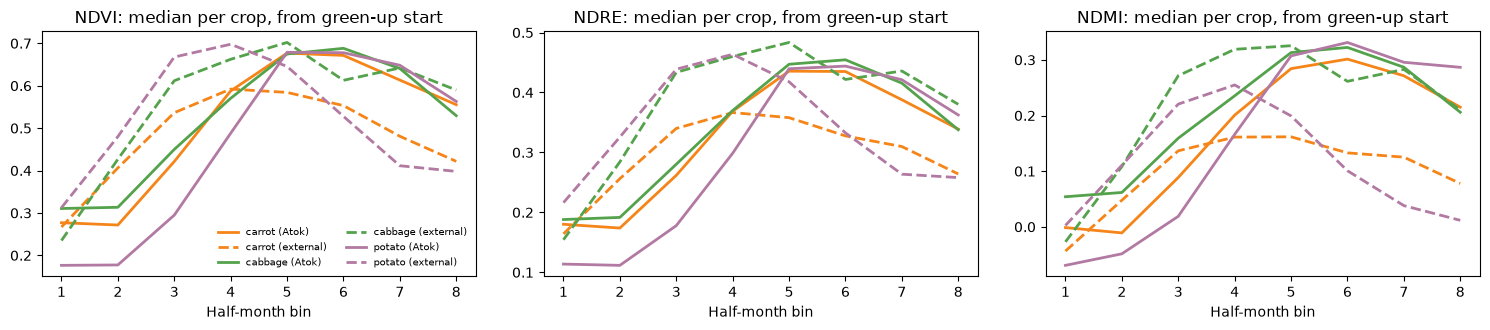

In [3]:
def smooth(values):
    return pd.DataFrame(values).interpolate(limit=2, limit_area="inside", axis=0).rolling(3, center=True, min_periods=2).median().to_numpy()


def cycle_bounds(ndvi, clear_column, prominence=0.15):
    finite = np.isfinite(ndvi)
    if finite.sum() < 20:
        return []
    peaks = find_peaks(np.where(finite, ndvi, np.nanmin(ndvi)), prominence=prominence, distance=4)[0]
    bounds = []
    for index, peak in enumerate(peaks):
        if not finite[peak]:
            continue
        previous_peak = peaks[index - 1] if index > 0 else -1
        next_peak = peaks[index + 1] if index + 1 < len(peaks) else len(ndvi)
        left = np.arange(max(0, peak - 12, previous_peak + 1), peak)
        right = np.arange(peak + 1, min(len(ndvi), peak + 13, next_peak))
        left, right = left[finite[left]], right[finite[right]]
        if not len(left) or not len(right):
            continue
        start, end = left[np.argmin(ndvi[left])], right[np.argmin(ndvi[right])]
        if 4 <= end - start <= 16 and clear_column[start:end + 1].mean() >= 0.6:
            bounds.append((start, peak, end))
    return bounds


def fill_gaps(values):
    """values: (L, V) with NaN rows -> linear interpolation, nearest value at the edges."""
    frame = pd.DataFrame(values)
    return frame.interpolate(limit_direction="both").to_numpy()


def cycle_samples(rows, cols, keep_cycle=None):
    """Cycle windows for the given pixels; keep_cycle(start, peak, end) can filter which cycles to keep."""
    series = add_indices(np.moveaxis(cube[:, :, rows, cols], 1, -1))  # (T, N, 8)
    clear = np.isfinite(series).all(-1)
    ndvi_smooth = smooth(series[:, :, VARS.index("NDVI")])
    records, matrices = [], []
    for j in range(len(rows)):
        for start, peak, end in cycle_bounds(ndvi_smooth[:, j], clear[:, j]):
            if start + BINS > len(SLOTS) or (keep_cycle and not keep_cycle(start, peak, end)):
                continue
            values = series[start:start + BINS, j, :]
            if np.isfinite(values).all(axis=1).sum() < 6:
                continue
            matrices.append(fill_gaps(values))
            records.append({"pixel": j, "row": rows[j], "col": cols[j], "start_slot": start, "peak_slot": peak, "end_slot": end})
    meta = pd.DataFrame(records)
    features = pd.DataFrame(np.stack(matrices).reshape(len(matrices), -1), columns=FEATURES) if matrices else pd.DataFrame(columns=FEATURES)
    return pd.concat([meta, features], axis=1)


atok_frames = []
for area in LABEL_AREAS:
    rr, cc = np.nonzero(interiors[area])
    samples = cycle_samples(rr, cc)
    growth_months = [sorted({SLOTS[s][1] for s in range(a, p + 1)}) for a, p in zip(samples["start_slot"], samples["peak_slot"])]
    priors = np.array([area_priors[area][[m - 1 for m in gm]].mean(0) for gm in growth_months])
    samples["crop"] = np.where(priors.max(1) >= 0.6, np.asarray(CROPS)[priors.argmax(1)], None)
    samples["label_strength"] = priors.max(1)
    samples["field"] = area
    samples["group"] = area
    samples["source"] = "atok"
    atok_frames.append(samples)
atok = pd.concat(atok_frames, ignore_index=True)
atok = atok[atok["crop"].notna() & np.isfinite(atok[FEATURES]).all(axis=1)].reset_index(drop=True)
atok["year"] = SLOT_DATE[atok["start_slot"]].year

external_frames = []
for table, group_column in (("cropharvest", None), ("francecrops_s4a", "source_dataset")):
    path = EXTERNAL_INPUTS / f"{table}.csv"
    if not path.is_file():
        print(f"{path.name} missing: run notebook 07 to cache it; external experiments will be skipped.")
        continue
    frame = pd.read_csv(path, dtype={"partition_group": str})
    prefix = frame[group_column].astype(str) if group_column else "cropharvest"
    external_frames.append(pd.DataFrame({"crop": frame["crop"], "group": prefix + "|" + frame["partition_group"].astype(str),
                                         "field": "external", "source": table, "label_strength": 1.0, **{c: frame[c] for c in FEATURES}}))
external = pd.concat(external_frames, ignore_index=True) if external_frames else pd.DataFrame(columns=["crop", "group", "source"] + FEATURES)
external = external[external["crop"].isin(CROPS) & np.isfinite(external[FEATURES]).all(axis=1)].reset_index(drop=True)

print(f"Atok labeled cycles: {len(atok):,} | external samples: {len(external):,}")
display(atok.pivot_table(index="field", columns="crop", values="pixel", aggfunc="size", fill_value=0))
display(external.pivot_table(index="source", columns="crop", values="group", aggfunc="nunique", fill_value=0).rename_axis("external parcels"))

figure, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for axis, var in zip(axes, ["NDVI", "NDRE", "NDMI"]):
    columns = [f"bin_{b:02d}_{var}" for b in range(1, BINS + 1)]
    for crop in TARGET_CROPS:
        for frame, style, label in ((atok, "-", "Atok"), (external, "--", "external")):
            rows = frame[frame["crop"] == crop]
            if len(rows):
                axis.plot(range(1, BINS + 1), rows[columns].median(), style, color=COLORS[crop], lw=2, label=f"{crop} ({label})")
    axis.set_title(f"{var}: median per crop, from green-up start")
    axis.set_xlabel("Half-month bin")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
figure.tight_layout()
figure.savefig(FIGURES / "atok_vs_external_profiles.png", dpi=150)
plt.show()

### 2.1 Reference data profile

One table for every training and test source: samples, fields or parcels, class share, where the samples are, which years they cover, and how their labels relate to time. It is saved as `reference_data_profile.csv`. Below it are the imbalance ratios (largest ÷ smallest class) per source.

**Temporal match.** The Atok labels are not dated observations. They come from the crop rotations the adviser described for each area, transcribed by hand into `CALENDAR` (section 1). No planting or harvest dates were recorded, so the same month pattern is applied to every year from 2019 to 2026. A cycle that greens up in March gets potato on Area 2 in every year, whether or not potato was planted there that year. Area 3 (cabbage), B2 and Area 5 (other crop) are described as year-round, so their labels say what grows there but not when. The external labels are different: each CropHarvest, Sen4AgriNet and FranceCrops sample belongs to one stated season and is matched to imagery from that season. For Atok, temporal correspondence therefore means agreement with a described rotation, not with a recorded planting. This is why every Atok score in this notebook is agreement with the calendar, not accuracy.

**Imbalance.** Within Atok, each crop comes from one to three fields, and potato comes only from Area 2. In the pooled external data, cabbage, carrot and potato come from different source mixes (FranceCrops has only cabbage, Sen4AgriNet only carrot and potato), so crop and source are partly confounded. Section 3 compensates for unequal sample counts by weighting (each crop gets equal total weight, split across its fields or parcels), not by resampling. Weighting cannot add fields that do not exist.

In [4]:
SOURCE_NAMES = {"atok": "Atok", "cropharvest": "CropHarvest", "sen4agrinet": "Sen4AgriNet", "francecrops": "FranceCrops"}
SEASONAL_AREAS = {row[0] for row in CALENDAR if row[3] != ALL_MONTHS and row[4] >= 0.5}  # areas whose main crops have months
COUNTRY_NAMES = {"ES": "Spain (Catalonia)", "francecrops": "France"}  # Sen4AgriNet/FranceCrops groups start with a region code
PIXEL_HA = abs(WINDOW_TRANSFORM.a * WINDOW_TRANSFORM.e) / 10_000

external_meta = []  # country, coordinates and year are not kept in `external`, so read them again without the features
for table, year_column in (("cropharvest", "year"), ("francecrops_s4a", "source_year")):
    path = EXTERNAL_INPUTS / f"{table}.csv"
    if path.is_file():
        meta = pd.read_csv(path, usecols=lambda c: not c.startswith("bin_"), dtype={"partition_group": str})
        external_meta.append(pd.DataFrame({
            "source": meta["source_dataset"] if "source_dataset" in meta else table, "crop": meta["crop"],
            "parcel": meta["partition_group"], "year": meta[year_column],
            "country": meta["country"] if "country" in meta else meta["partition_group"].str.split("|").str[0].replace(COUNTRY_NAMES),
            "lat": meta["lat"], "lon": meta["lon"]}))
external_meta = pd.concat(external_meta, ignore_index=True) if external_meta else pd.DataFrame(
    columns=["source", "crop", "parcel", "year", "country", "lat", "lon"])
external_meta = external_meta[external_meta["crop"].isin(CROPS)]

profile_rows = []
for crop, rows in atok.groupby("crop"):
    fields = rows["field"].value_counts()
    profile_rows.append({
        "source": "Atok", "crop": crop, "samples": len(rows), "fields / parcels": len(fields),
        "spatial": ", ".join(f"{f} {n} ({interiors[f].sum() * PIXEL_HA:.1f} ha)" for f, n in fields.items()),
        "years": f"{rows['year'].min()}-{rows['year'].max()}",
        "label timing": "; ".join(f"{kind}: {', '.join(f for f in fields.index if (f in SEASONAL_AREAS) == seasonal)}"
                                  for kind, seasonal in (("rotation, undated", True), ("year-round, no season", False))
                                  if any((f in SEASONAL_AREAS) == seasonal for f in fields.index)),
        "median label strength": rows["label_strength"].median()})
for (source, crop), rows in external_meta.groupby(["source", "crop"]):
    countries = rows["country"].value_counts()
    profile_rows.append({
        "source": SOURCE_NAMES.get(source, source), "crop": crop, "samples": len(rows), "fields / parcels": rows["parcel"].nunique(),
        "spatial": ", ".join(f"{c} {n}" for c, n in countries.items())
                   + f" | lat {rows['lat'].min():.1f} to {rows['lat'].max():.1f}, lon {rows['lon'].min():.1f} to {rows['lon'].max():.1f}",
        "years": ", ".join(str(y) for y in sorted(rows["year"].unique())),
        "label timing": "dated season", "median label strength": 1.0})
profile = pd.DataFrame(profile_rows)
profile.insert(3, "share of source (%)", 100 * profile["samples"] / profile.groupby("source")["samples"].transform("sum"))
profile.to_csv(OUTPUT / "reference_data_profile.csv", index=False)
with pd.option_context("display.max_colwidth", 200, "display.max_columns", None):
    display(profile.set_index(["source", "crop"]))

pooled = [("Atok", atok["crop"], atok["field"]),
          ("External (pooled)", external_meta["crop"], external_meta["source"] + "|" + external_meta["parcel"].astype(str))]
pooled += [(SOURCE_NAMES.get(s, s), rows["crop"], rows["parcel"]) for s, rows in external_meta.groupby("source")]
for name, crops, groups in pooled:
    samples, parcels = crops.value_counts(), groups.groupby(crops).nunique()
    print(f"{name}: {len(crops):,} samples, {groups.nunique():,} fields/parcels, {len(samples)} crops | largest/smallest class: "
          f"{samples.max() / samples.min():.1f}x samples, {parcels.max() / parcels.min():.1f}x fields/parcels")
print("External crop by source:", external_meta.groupby("crop")["source"].unique().map(lambda s: ", ".join(SOURCE_NAMES.get(x, x) for x in s)).to_dict())
top_field = atok.groupby("crop")["field"].agg(lambda s: (s.value_counts().index[0], s.value_counts(normalize=True).iloc[0]))
print("Atok cycles from one field:", ", ".join(f"{crop} {field} {share:.0%}" for crop, (field, share) in top_field.items()))

samples  share of source (%)  fields / parcels                                                                                                           spatial       years  \
source      crop                                                                                                                                                                                       
Atok        cabbage        1109               26.833                 3                                                         B1 412 (3.1 ha), Area 2 385 (4.4 ha), Area 3 312 (0.2 ha)   2019-2026   
            carrot         1670               40.406                 2                                                                             B1 1142 (3.1 ha), Area 2 528 (4.4 ha)   2019-2026   
            other_crop      707               17.106                 2                                                                              B2 598 (0.5 ha), Area 5 109 (0.3 ha)   2019-2026   
            potato          647               15.654                 1                                                                                               Area 2 647 (4.4 ha)   2019-2026   
CropHarvest cabbage         359               31.136                20  Martinique (FR) 148, Senegal 127, France 76, Madagascar 4, Réunion (FR) 4 | lat -21.2 to 49.1, lon -61.2 to 55.5  2019, 2021   
            carrot          294               25.499                45            Madagascar 123, Réunion (FR) 100, France 60, Martinique (FR) 11 | lat -21.3 to 49.1, lon -61.1 to 55.6        2019   
            potato          500               43.365                50                                 France 205, Réunion (FR) 156, Madagascar 139 | lat -21.4 to 49.1, lon 2.0 to 55.6        2019   
FranceCrops cabbage         500              100.000                18                                                                    France 500 | lat 43.3 to 50.4, lon -3.2 to 7.5        2022   
Sen4AgriNet carrot          500               50.000                26                                                          Spain (Catalonia) 500 | lat 41.2 to 41.8, lon 0.7 to 3.0        2020   
            potato          500               50.000               132                                                          Spain (Catalonia) 500 | lat 40.6 to 42.4, lon 0.4 to 3.1        2020   

                                                                        label timing  median label strength  
source      crop                                                                                             
Atok        cabbage     rotation, undated: B1, Area 2; year-round, no season: Area 3                  0.694  
            carrot                                     rotation, undated: B1, Area 2                  0.667  
            other_crop                             year-round, no season: B2, Area 5                  1.000  
            potato                                         rotation, undated: Area 2                  0.700  
CropHarvest cabbage                                                     dated season                  1.000  
            carrot                                                      dated season                  1.000  
            potato                                                      dated season                  1.000  
FranceCrops cabbage                                                     dated season                  1.000  
Sen4AgriNet carrot                                                      dated season                  1.000  
            potato                                                      dated season                  1.000

Atok: 4,133 samples, 5 fields/parcels, 4 crops | largest/smallest class: 2.6x samples, 3.0x fields/parcels
External (pooled): 2,653 samples, 291 fields/parcels, 3 crops | largest/smallest class: 1.3x samples, 4.8x fields/parcels
CropHarvest: 1,153 samples, 115 fields/parcels, 3 crops | largest/smallest class: 1.7x samples, 2.5x fields/parcels
FranceCrops: 500 samples, 18 fields/parcels, 1 crops | largest/smallest class: 1.0x samples, 1.0x fields/parcels
Sen4AgriNet: 1,000 samples, 158 fields/parcels, 2 crops | largest/smallest class: 1.0x samples, 5.1x fields/parcels
External crop by source: {'cabbage': 'CropHarvest, FranceCrops', 'carrot': 'CropHarvest, Sen4AgriNet', 'potato': 'CropHarvest, Sen4AgriNet'}
Atok cycles from one field: cabbage B1 37%, carrot B1 68%, other_crop B2 85%, potato Area 2 100%


## 3. Training setups

| Setup | Training data for each held-out Atok field |
|---|---|
| Atok only | The other Atok fields |
| External only | CropHarvest and France |
| Combined | External plus the other Atok fields |
| Combined, Atok-weighted | Same as combined, but Atok and external each get half the total weight |

Each setup is run with a Random Forest (500 trees, sqrt features, min leaf 2) and with standardized logistic regression, which did best on the external data in notebook 07. Within a source, each crop has equal weight split across its groups (Atok fields or external parcels), and Atok rows are also weighted by label strength.

In [5]:
def balanced_weights(frame):
    weights = frame["label_strength"].to_numpy(dtype=float).copy()
    for crop, rows in frame.groupby("crop"):
        groups = rows["group"].unique()
        for group in groups:
            mask = ((frame["crop"] == crop) & (frame["group"] == group)).to_numpy()
            weights[mask] = weights[mask] / weights[mask].sum() / len(groups)
    return weights * len(weights) / weights.sum()


def training_set(setup, held_out_field):
    other_atok = atok[atok["field"] != held_out_field]
    if setup == "Atok only":
        return other_atok, balanced_weights(other_atok)
    if setup == "External only":
        return external, balanced_weights(external)
    combined = pd.concat([external, other_atok], ignore_index=True)
    if setup == "Combined":
        return combined, balanced_weights(combined)
    w_external, w_atok = balanced_weights(external), balanced_weights(other_atok)
    weights = np.concatenate([w_external / w_external.sum(), w_atok / w_atok.sum()])
    return combined, weights * len(weights) / weights.sum()


def make_model(kind):
    if kind == "Random Forest":
        return RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=2, n_jobs=-1, random_state=SEED)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))


def fit(kind, frame, weights):
    model = make_model(kind)
    X, y = frame[FEATURES].to_numpy(), frame["crop"].to_numpy()
    if kind == "Random Forest":
        return model.fit(X, y, sample_weight=weights)
    return model.fit(X, y, logisticregression__sample_weight=weights)


def crop_probabilities(model, frame):
    proba = model.predict_proba(frame[FEATURES].to_numpy())
    out = np.zeros((len(frame), len(CROPS)))
    for index, crop in enumerate(model.classes_):
        out[:, CROPS.index(crop)] = proba[:, index]
    return out


SETUPS = ["Atok only", "External only", "Combined", "Combined, Atok-weighted"] if len(external) else ["Atok only"]
MODELS = ["Random Forest", "Logistic regression"]
prediction_rows = []
for setup in SETUPS:
    for kind in MODELS:
        cached_external_model = None
        for field in LABEL_AREAS:
            test = atok[atok["field"] == field]
            if not len(test):
                continue
            if setup == "External only":
                if cached_external_model is None:  # same model for every held-out field
                    cached_external_model = fit(kind, *training_set(setup, field))
                model, train_crops = cached_external_model, set(external["crop"])
            else:
                train, weights = training_set(setup, field)
                model, train_crops = fit(kind, train, weights), set(train["crop"])
            proba = crop_probabilities(model, test)
            answer = np.where(proba.max(1) >= ABSTAIN_BELOW, np.asarray(CROPS)[proba.argmax(1)], "unknown")
            for t, a, p in zip(test["crop"], answer, proba.max(1)):
                prediction_rows.append({"setup": setup, "model": kind, "field": field, "truth": t, "answer": a,
                                        "confidence": p, "crop_in_training": t in train_crops})
predictions = pd.DataFrame(prediction_rows)
predictions.to_csv(OUTPUT / "held_out_field_predictions.csv", index=False)
print(f"{len(predictions):,} held-out cycle predictions")

33,064 held-out cycle predictions


## 4. Results on unseen Atok fields

For each setup and crop: the share of held-out cycles that are correct, wrong or unknown, and the precision (how often the model is right when it gives that crop). Precision should be compared with the share of that crop among the held-out cycles, which is what random guessing would give. A crop that is not in the training data counts as 0 correct. The main number is the mean correct over carrot, cabbage and potato, compared with random guessing (0.25) and with Baseline 0 from notebook 08 on the same three crops: its held-out-polygon recall for each crop, averaged as in notebook 08's section 12.7. Potato is only in Area 2, so Baseline 0 never sees it once Area 2 is held out; by the rule above it counts as 0 correct.

,setup,model,mean_correct_target,answered_share,carrot_correct,cabbage_correct,potato_correct,other_crop_correct
0,External only,Logistic regression,33%,89%,50%,41%,8%,0%
1,"Combined, Atok-weighted",Logistic regression,16%,79%,19%,29%,0%,6%
2,Atok only,Logistic regression,11%,86%,14%,19%,0%,7%
3,Combined,Logistic regression,10%,88%,18%,13%,0%,11%
4,External only,Random Forest,8%,40%,8%,12%,3%,0%
5,Atok only,Random Forest,4%,42%,6%,6%,0%,0%
6,"Combined, Atok-weighted",Random Forest,4%,29%,5%,6%,0%,0%
7,Combined,Random Forest,1%,54%,1%,1%,0%,0%


,setup,model,carrot_unknown,carrot_precision,cabbage_unknown,cabbage_precision,potato_unknown,potato_precision
0,External only,Logistic regression,13%,49%,10%,36%,11%,7%
1,"Combined, Atok-weighted",Logistic regression,23%,33%,25%,27%,13%,0%
2,Atok only,Logistic regression,12%,22%,21%,17%,16%,0%
3,Combined,Logistic regression,13%,50%,13%,23%,10%,1%
4,External only,Random Forest,60%,58%,51%,30%,71%,2%
5,Atok only,Random Forest,65%,17%,70%,10%,42%,0%
6,"Combined, Atok-weighted",Random Forest,75%,19%,83%,15%,59%,0%
7,Combined,Random Forest,51%,71%,42%,2%,42%,1%


Baseline 0 unseen-field recall per crop (notebook 08 v2): {'carrot': 0.064, 'cabbage': 0.254, 'potato': 0.0} -> mean 0.106 | random guess: 0.25
Share of held-out cycles per crop: {'carrot': 0.4, 'cabbage': 0.27, 'potato': 0.16, 'other_crop': 0.17}


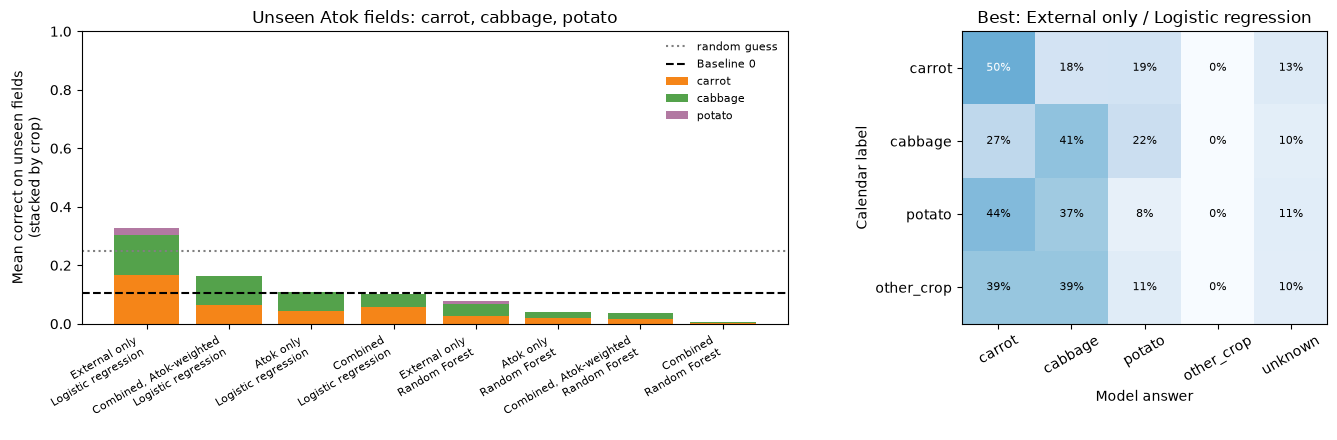

In [6]:
summary_rows = []
for (setup, kind), part in predictions.groupby(["setup", "model"]):
    row = {"setup": setup, "model": kind}
    for crop in CROPS:
        truth = part[part["truth"] == crop]
        called = part[part["answer"] == crop]
        if not len(truth):
            continue
        row[f"{crop}_correct"] = (truth["answer"] == crop).mean()
        row[f"{crop}_unknown"] = (truth["answer"] == "unknown").mean()
        row[f"{crop}_precision"] = (called["truth"] == crop).mean() if len(called) else np.nan
    row["mean_correct_target"] = np.mean([row.get(f"{c}_correct", 0.0) for c in TARGET_CROPS])
    row["answered_share"] = (part["answer"] != "unknown").mean()
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows).sort_values("mean_correct_target", ascending=False).reset_index(drop=True)
summary.to_csv(OUTPUT / "held_out_field_summary.csv", index=False)
baseline0_per_crop = pd.Series(np.nan, index=TARGET_CROPS)
if BASELINE0.is_file():
    lopo = pd.DataFrame(json.loads(BASELINE0.read_text())["leave_one_polygon_out"])
    tested_recall = lopo[lopo["status"] == "tested"].groupby("class")["recall"].mean()
    baseline0_per_crop = tested_recall.reindex(TARGET_CROPS).fillna(0.0)  # untestable (potato: one field only) counts as 0 correct
baseline0_recall = float(baseline0_per_crop.mean())
display(summary[["setup", "model", "mean_correct_target", "answered_share"] + [f"{c}_correct" for c in CROPS if f"{c}_correct" in summary]]
        .style.format({c: "{:.0%}" for c in summary.columns if c not in ("setup", "model")}, na_rep="-"))
display(summary[["setup", "model"] + [f"{c}_{m}" for c in TARGET_CROPS for m in ("unknown", "precision") if f"{c}_{m}" in summary]]
        .style.format({c: "{:.0%}" for c in summary.columns if c not in ("setup", "model")}, na_rep="-"))
print("Baseline 0 unseen-field recall per crop (notebook 08 v2):", baseline0_per_crop.round(3).to_dict(),
      f"-> mean {baseline0_recall:.3f} | random guess: 0.25")
base_rates = atok["crop"].value_counts(normalize=True).reindex(CROPS)
print("Share of held-out cycles per crop:", {c: round(float(v), 2) for c, v in base_rates.items()})

best = summary.iloc[0]
best_predictions = predictions[(predictions["setup"] == best["setup"]) & (predictions["model"] == best["model"])]
figure, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
labels = [f"{s}\n{m}" for s, m in zip(summary["setup"], summary["model"])]
bottom = np.zeros(len(summary))
for crop in TARGET_CROPS:
    values = summary[f"{crop}_correct"].fillna(0).to_numpy() / len(TARGET_CROPS) if f"{crop}_correct" in summary else np.zeros(len(summary))
    left.bar(range(len(summary)), values, bottom=bottom, color=COLORS[crop], label=crop)
    bottom += values
left.axhline(0.25, color="grey", ls=":", label="random guess")
if np.isfinite(baseline0_recall):
    left.axhline(baseline0_recall, color="black", ls="--", label="Baseline 0")
left.set_xticks(range(len(summary)), labels, rotation=30, ha="right", fontsize=8)
left.set_ylabel("Mean correct on unseen fields\n(stacked by crop)")
left.set_ylim(0, 1)
left.legend(frameon=False, fontsize=8)
left.set_title("Unseen Atok fields: carrot, cabbage, potato")
answer_labels = CROPS + ["unknown"]
matrix = confusion_matrix(best_predictions["truth"], best_predictions["answer"], labels=answer_labels)[: len(CROPS)]
shares = matrix / np.maximum(matrix.sum(1, keepdims=True), 1)
right.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CROPS)):
    for j in range(len(answer_labels)):
        right.text(j, i, f"{shares[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if shares[i, j] > 0.5 else "black")
right.set_xticks(range(len(answer_labels)), answer_labels, rotation=30)
right.set_yticks(range(len(CROPS)), CROPS)
right.set_xlabel("Model answer")
right.set_ylabel("Calendar label")
right.set_title(f"Best: {best['setup']} / {best['model']}")
figure.tight_layout()
figure.savefig(FIGURES / "held_out_field_results.png", dpi=150)
plt.show()

## 5. Final model

The setup with the best mean correct is refitted on all of its data and saved as `crop_type_model.joblib`. Its score is a bit optimistic, because the same held-out results were used to choose it. It is considered usable for crop maps only if it beats Baseline 0 by at least 0.10, beats random guessing for each crop it was trained on, and gets more than 0.25 correct for potato on Area 2.

In [7]:
final_train = pd.concat([external, atok], ignore_index=True) if best["setup"] != "Atok only" else atok
if best["setup"] == "External only":
    final_train = external
if best["setup"] == "Combined, Atok-weighted":
    w_external, w_atok = balanced_weights(external), balanced_weights(atok)
    final_weights = np.concatenate([w_external / w_external.sum(), w_atok / w_atok.sum()])
    final_weights *= len(final_weights) / final_weights.sum()
else:
    final_weights = balanced_weights(final_train)
final_model = fit(best["model"], final_train, final_weights)
joblib.dump({"model": final_model, "features": FEATURES, "classes": CROPS, "setup": best["setup"], "model_type": best["model"],
             "abstain_below": ABSTAIN_BELOW, "status": "unvalidated prototype"}, OUTPUT / "crop_type_model.joblib")

trained_targets = [c for c in TARGET_CROPS if c in set(final_train["crop"])]
checks = {
    "beats_baseline0_by_0.10": bool(np.isfinite(baseline0_recall) and best["mean_correct_target"] >= baseline0_recall + 0.10),
    "beats_random_each_trained_crop": bool(all(best.get(f"{c}_correct", 0) > 0.25 for c in trained_targets)),
    "potato_recognised": bool("potato" in trained_targets and best.get("potato_correct", 0) > 0.25),
}
verdict = {"best_setup": best["setup"], "best_model": best["model"], "mean_correct_target": round(float(best["mean_correct_target"]), 3),
           "baseline0_recall": None if not np.isfinite(baseline0_recall) else round(float(baseline0_recall), 3),
           "baseline0_recall_per_crop": {c: round(float(v), 3) for c, v in baseline0_per_crop.items()}, **checks,
           "usable_for_crop_maps": all(checks.values()),
           "note": "agreement with KML calendars on unseen Atok fields"}
(OUTPUT / "verdict.json").write_text(json.dumps(verdict, indent=2))
for key, value in verdict.items():
    print(f"{key}: {value}")

best_setup: External only
best_model: Logistic regression
mean_correct_target: 0.329
baseline0_recall: 0.106
baseline0_recall_per_crop: {'carrot': 0.064, 'cabbage': 0.254, 'potato': 0.0}
beats_baseline0_by_0.10: True
beats_random_each_trained_crop: False
potato_recognised: False
usable_for_crop_maps: False
note: agreement with KML calendars on unseen Atok fields


## 6. 2025 crop maps

Only active cropland pixels from notebook 09 are used. For early April, August and December 2025, the cycle each pixel is in gets the model's crop, or unknown if the probability is below 0.5. Cropland pixels without a cycle on that date are light grey. Outside the cropland, the notebook 09 land-activity map is shown as in notebook 08: perennial vegetation and bare / built ground are non-crop (dark grey), mixed / low-activity land is pale (it may include fallow fields, so it is not called non-crop), and diagonal hatching marks pixels with no Sentinel-2 data in any composite (the western part of the area of interest, outside the Atok boundary). These areas come from notebook 09's unsupervised map, not from this model, which only knows carrot, cabbage and potato. The maps are saved as GeoTIFFs (band 1 crop code, band 2 probability) and marked as an unvalidated prototype.

Area of interest: 41,115 pixels | active cropland 21,125 | non-crop 12,567 | mixed / low activity 2,314 | no imagery 5,109


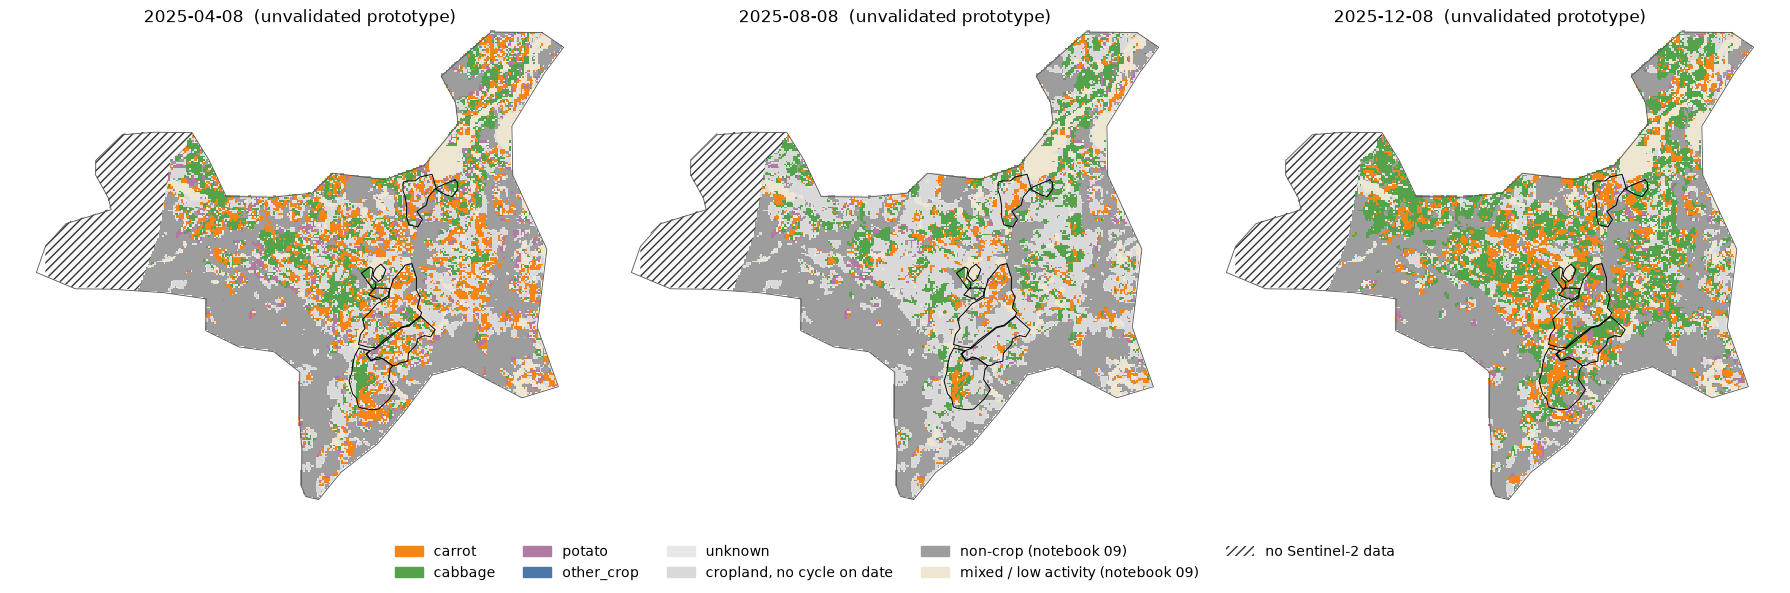

,cropland_pixels_in_a_cycle,share_of_cropland_in_a_cycle,carrot,cabbage,potato,other_crop,unknown
date,,,,,,,
2025-04-08,14517,69%,42%,32%,13%,0%,13%
2025-08-08,10087,48%,30%,50%,10%,0%,10%
2025-12-08,16943,80%,32%,54%,5%,0%,9%


In [8]:
if LAND_ACTIVITY.is_file():
    with rasterio.open(LAND_ACTIVITY) as source:
        land_activity = source.read(1)  # notebook 09 codes: 0 active cropland, 1 mixed / low activity, 2 perennial vegetation, 3 bare / built
else:
    print("Notebook 09 land-activity map missing: mapping all ROI pixels.")
    land_activity = np.where(roi_mask, 0.0, np.nan)
cropland = (land_activity == 0) & roi_mask
NON_CROP_COLOR, MIXED_COLOR = "#9D9D9D", "#EFE6D2"  # non-crop grey as in notebook 08
no_imagery = roi_mask & ~np.isfinite(cube).all(axis=1).any(0)  # no clear composite at all in 2019-2026
outside_cropland = np.where(roi_mask & np.isin(land_activity, [2, 3]), 0.0, np.where(roi_mask & (land_activity == 1), 1.0, np.nan))
print(f"Area of interest: {int(roi_mask.sum()):,} pixels | active cropland {int(cropland.sum()):,} | non-crop "
      f"{int((outside_cropland == 0).sum()):,} | mixed / low activity {int((outside_cropland == 1).sum()):,} | no imagery {int(no_imagery.sum()):,}")
map_dates = [i for i, (y, m, h) in enumerate(SLOTS) if y == 2025 and h == 1 and m in (4, 8, 12)]
rr, cc = np.nonzero(cropland)
map_samples = cycle_samples(rr, cc, keep_cycle=lambda s, p, e: any(s <= d <= e for d in map_dates))
map_proba = crop_probabilities(final_model, map_samples) if len(map_samples) else np.zeros((0, len(CROPS)))
answer_names = CROPS + ["unknown"]
figure, axes = plt.subplots(1, len(map_dates), figsize=(6 * len(map_dates), 5.8))
map_rows = []
for axis, date in zip(axes, map_dates):
    active = ((map_samples["start_slot"] <= date) & (map_samples["end_slot"] >= date)).to_numpy()
    code = np.where(map_proba[active].max(1) >= ABSTAIN_BELOW, map_proba[active].argmax(1), len(CROPS)).astype(float)
    crop_grid, probability_grid = np.full((H, W), np.nan, "float32"), np.full((H, W), np.nan, "float32")
    crop_grid[map_samples.loc[active, "row"], map_samples.loc[active, "col"]] = code
    probability_grid[map_samples.loc[active, "row"], map_samples.loc[active, "col"]] = map_proba[active].max(1)
    label = SLOT_DATE[date].strftime("%Y-%m-%d")
    with rasterio.open(OUTPUT / f"crop_type_{label}.tif", "w", driver="GTiff", height=H, width=W, count=2, dtype="float32",
                       crs=GRID_CRS, transform=WINDOW_TRANSFORM, nodata=np.nan) as destination:
        destination.write(crop_grid, 1)
        destination.write(probability_grid, 2)
        destination.update_tags(codes=", ".join(f"{i}={n}" for i, n in enumerate(answer_names)), status="unvalidated prototype",
                                model=f"{best['setup']} / {best['model']}")
    background = np.where(cropland, 0.0, np.nan)
    axis.imshow(np.where(roi_mask, 1.0, np.nan), cmap=ListedColormap(["#FAFAFA"]), vmin=0, vmax=1)
    axis.imshow(background, cmap=ListedColormap(["#D9D9D9"]), vmin=0, vmax=1)
    axis.imshow(outside_cropland, cmap=ListedColormap([NON_CROP_COLOR, MIXED_COLOR]), vmin=-0.5, vmax=1.5, interpolation="nearest")
    if no_imagery.any():
        hatched = axis.contourf(no_imagery.astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"])
        hatched.set_edgecolor("#333333")
        hatched.set_linewidth(0)
    axis.imshow(crop_grid, cmap=ListedColormap([COLORS[n] for n in answer_names]), vmin=-0.5, vmax=len(answer_names) - 0.5, interpolation="nearest")
    for name, geom in polygons["grid_geometry"].items():
        xs, ys = geom.exterior.xy
        px = [~WINDOW_TRANSFORM * (x, y) for x, y in zip(xs, ys)]
        axis.plot([p[0] for p in px], [p[1] for p in px], color="black", lw=0.7)
    xs, ys = roi_grid.exterior.xy
    px = [~WINDOW_TRANSFORM * (x, y) for x, y in zip(xs, ys)]
    axis.plot([p[0] for p in px], [p[1] for p in px], color="#555555", lw=0.6)
    axis.set_title(f"{label}  (unvalidated prototype)")
    axis.axis("off")
    shares = pd.Series(code).map(dict(enumerate(answer_names))).value_counts(normalize=True)
    map_rows.append({"date": label, "cropland_pixels_in_a_cycle": int(active.sum()), "share_of_cropland_in_a_cycle": active.sum() / cropland.sum(),
                     **{n: shares.get(n, 0.0) for n in answer_names}})
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [COLORS[n] for n in answer_names] + ["#D9D9D9", NON_CROP_COLOR, MIXED_COLOR]]
handles.append(mpatches.Patch(facecolor="white", edgecolor="#333333", hatch="////", lw=0))
figure.legend(handles, answer_names + ["cropland, no cycle on date", "non-crop (notebook 09)", "mixed / low activity (notebook 09)",
                                       "no Sentinel-2 data"], loc="lower center", ncol=5, frameon=False)
figure.tight_layout(rect=(0, 0.08, 1, 1))
figure.savefig(FIGURES / "crop_type_maps_2025.png", dpi=150)
plt.show()
display(pd.DataFrame(map_rows).set_index("date").style.format({n: "{:.0%}" for n in answer_names + ["share_of_cropland_in_a_cycle"]}))